# Numerical Methods for Initial Value Problems
## Assignment — Implementation and Convergence
**Computational Techniques for Differential Equations — Academic Year 2026/2027**

**Name: Jose Antonio Peña Mulero**

### Objective
Implement the one-step and linear multistep methods studied in class, and verify their orders of convergence using two problems with known exact solutions: a scalar nonlinear equation and a linear system.

Your implementations must use the same interface for both problems. This will allow you to reuse the time integrators later, when a spatial discretization of a PDE produces a system of ODEs through the **method of lines**.

Implement the time-stepping formulas yourself. You may use NumPy and library routines for solving algebraic equations. Do not use a library ODE integrator to perform the time stepping.


## Part A — Implementation
### A.1. A common interface
Consider the initial value problem
$$
\mathbf u'(t)=f(t,\mathbf u(t)),\qquad t_0\leq t\leq T,
\qquad \mathbf u(t_0)=\mathbf u_0\in\mathbb R^d.
$$
Implement each method as a function with the interface
```python
t, U = method(f, tspan, U0, N)
```
where:
- `f(t, U)` receives a time and a one-dimensional state array of length `d`, and returns a one-dimensional array of the same length;
- `tspan = (t0, T)`, with `T > t0`;
- `U0` is a one-dimensional array of length `d`;
- `N` is the number of uniform time steps, so $k=(T-t_0)/N$;
- `t` contains all $N+1$ time levels, including both endpoints;
- `U` has shape `(d, N + 1)`, and `U[:, n]` approximates $\mathbf u(t_n)$.

**Represent a scalar problem by a vector of length one.** The integrators must work for any compatible dimension without changing their formulas. Use array operations rather than separate formulas for each component. Check input dimensions, preserve previous states when storing new values, and do not modify `U0` in place.

The right-hand side and initial condition belong to the problem definition, not inside the integrators. For example, a matrix enters through
```python
f = lambda t, U: A @ U + g(t)
```
The integrator itself still takes a function. Use one consistent argument order, **`f(t, U)`**, throughout the assignment.


In [646]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import root


In [647]:
def start_methods(tspan:tuple, U0, N:int):
    """Shared code among all methods. Initializes k, t and U.
    """
    # Check tspan interval
    if len(tspan)!=2:
        raise ValueError("tspan not an interval")
    
    t0, T = tspan
    
    if t0>=T:
        raise ValueError("tspan not well defined interval (t0 >= T)")
    
    # N positive interval
    if N <=0:
        raise ValueError("N is not positive")
    
    # Discretize
    k = (T-t0)/N
    t = np.linspace(t0, T, N+1)
    
    # Initialize U
        
    if U0.ndim != 1: # Shape (d,)
        raise ValueError("U0 not an unidimensional array") 
    
    d = U0.size
    
    U = np.zeros((d, N+1))
    # Set initial conditions
    U[:, 0] = U0
    
    return k, t, U
    

### A.2. One-step methods
In the formulas below, $\mathbf U^n$ is a vector and $F^n=f(t_n,\mathbf U^n)$.

**1. Forward Euler (FE), order 1**
$$
\mathbf U^{n+1}=\mathbf U^n+kF^n.
$$

**2. Backward Euler (BE), order 1**
$$
\mathbf U^{n+1}=\mathbf U^n+kf(t_{n+1},\mathbf U^{n+1}).
$$

**3. Explicit midpoint RK2, order 2**
$$
\begin{aligned}
K_1&=f(t_n,\mathbf U^n),\\
K_2&=f(t_n+k/2,\mathbf U^n+(k/2)K_1),\\
\mathbf U^{n+1}&=\mathbf U^n+kK_2.
\end{aligned}
$$

**4. Explicit trapezoidal RK2 (improved Euler), order 2**
$$
\begin{aligned}
K_1&=f(t_n,\mathbf U^n),\\
K_2&=f(t_n+k,\mathbf U^n+kK_1),\\
\mathbf U^{n+1}&=\mathbf U^n+\frac{k}{2}(K_1+K_2).
\end{aligned}
$$

**5. Heun RK3, order 3**
$$
\begin{aligned}
K_1&=f(t_n,\mathbf U^n),\\
K_2&=f(t_n+k/3,\mathbf U^n+(k/3)K_1),\\
K_3&=f(t_n+2k/3,\mathbf U^n+(2k/3)K_2),\\
\mathbf U^{n+1}&=\mathbf U^n+\frac{k}{4}(K_1+3K_3).
\end{aligned}
$$

**6. Classical RK4, order 4**
$$
\begin{aligned}
K_1&=f(t_n,\mathbf U^n),\\
K_2&=f(t_n+k/2,\mathbf U^n+(k/2)K_1),\\
K_3&=f(t_n+k/2,\mathbf U^n+(k/2)K_2),\\
K_4&=f(t_n+k,\mathbf U^n+kK_3),\\
\mathbf U^{n+1}&=\mathbf U^n+\frac{k}{6}(K_1+2K_2+2K_3+K_4).
\end{aligned}
$$

**7. Implicit trapezoidal method, order 2**
$$
\mathbf U^{n+1}=\mathbf U^n+
\frac{k}{2}\left[F^n+f(t_{n+1},\mathbf U^{n+1})\right].
$$
The implicit trapezoidal method and explicit trapezoidal RK2 are different methods. Implement both.


In [648]:
# Implement the explicit one-step methods here.
# A reusable rk4_step(f, t, U, k) function will also help initialize multistep methods.


In [649]:
def forward_euler(f, tspan, U0, N):
    k, t, U = start_methods(tspan, U0, N)

    for n in range(N):
        t_n = t[n]
        U_n = U[:, n]
        U[:,n+1] = U_n + k*f(t_n, U_n)
    
    return t, U


In [650]:
def midpoint_rk2(f, tspan, U0, N):
    k, t, U = start_methods(tspan, U0, N)
    
    for n in range(N):
        t_n = t[n]
        U_n = U[:, n]
        K1 = f(t_n, U_n)
        K2 = f(t_n+k/2, U_n + (k/2)*K1)
        
        U[:,n+1] = U_n + k*K2

    return t, U

In [651]:
def explicit_trapezoidal_rk2(f, tspan, U0, N):
    k, t, U = start_methods(tspan, U0, N)
    
    for n in range(N):
        t_n = t[n]
        U_n = U[:, n]
        K1 = f(t_n, U_n)
        K2 = f(t_n+k, U_n + k*K1)
        
        U[:,n+1] = U_n + (k/2)*(K1+K2)

    return t, U

In [652]:
def heun_rk3(f, tspan, U0, N):
    k, t, U = start_methods(tspan, U0, N)
    
    for n in range(N):
        t_n = t[n]
        U_n = U[:, n]
        K1 = f(t_n, U_n)
        K2 = f(t_n+k/3, U_n + (k/3)*K1)
        K3 = f(t_n + 2*k/3, U_n + (2*k/3)*K2)
        
        U[:,n+1] = U_n + (k/4)*(K1+3*K3)

    return t, U

In [653]:
def rk4_step(f, t_n, U_n, k):
    """Returns the next step of rk4"""
    K1 = f(t_n, U_n)
    K2 = f(t_n + k/2, U_n + k*K1/2)
    K3 = f(t_n + k/2, U_n + k*K2/2)
    K4 = f(t_n + k, U_n + k*K3)
    
    return U_n + (k/6)*(K1 + 2*K2 + 2*K3 + K4)


def rk4(f, tspan, U0, N):
    k, t, U = start_methods(tspan, U0, N)
    
    for n in range(N):
        t_n = t[n]
        U_n = U[:, n]

        U[:,n+1] = rk4_step(f, t_n, U_n, k)

    return t, U

### A.3. Implicit algebraic equations
For an implicit method, formulate a residual $R(V)$ whose zero gives the new state. For example, backward Euler requires solving
$$
R(V)=V-\mathbf U^n-kf(t_{n+1},V)=0.
$$
Use the same residual formulation for scalar and vector problems. Do not hard-code the quadratic formula for the scalar test problem.

You may use the helper below; implementing Newton's method is **not required**. Your task is to construct the correct residual for each implicit method and call the algebraic solver at every step.

Use a forward Euler prediction as the initial guess for the implicit one-step methods, and $2\mathbf U^n-\mathbf U^{n-1}$ for implicit two-step methods. If the algebraic equation has multiple roots, seek the solution connected to the preceding state as $k\to0$.

The helper checks the residual, including when the solver reports poor progress near a root. If this check fails, it raises an exception. Do not silently continue a failed integration. Report the tolerance used; if fine-step convergence is obscured, investigate algebraic errors and roundoff before drawing conclusions.


In [654]:
def solve_implicit(residual, guess, tol=1e-12):
    """Provided algebraic solver; returns a state with a small scaled residual."""
    guess = np.asarray(guess, dtype=float)
    result = root(residual, guess, tol=tol)
    V = np.asarray(result.x, dtype=float)
    r = np.asarray(residual(V), dtype=float)
    
    if r.shape != guess.shape:
        raise ValueError("The residual must have the same shape as the state.")
    
    scale = max(1.0, np.linalg.norm(V, ord=np.inf))
    
    if (not np.all(np.isfinite(V)) or not np.all(np.isfinite(r))
            or np.linalg.norm(r, ord=np.inf) > tol * scale):
        raise RuntimeError(f"Implicit solve failed: {result.message}")
    
    return V.copy()

# Implement backward Euler and the implicit trapezoidal method here.


In [655]:
def backward_euler(f, tspan, U0, N):
    k, t, U = start_methods(tspan, U0, N)
    
    
    for n in range(N):
        
        t_n = t[n]
        U_n = U[:, n]
        
        
        guess = U_n + k*f(t_n, U_n)
        residual = lambda V: V - U_n - k*f(t[n+1], V)
        
        U[:,n+1] = solve_implicit(residual, guess)
    
    return t, U

In [656]:
def implicit_trapezoidal(f, tspan, U0, N):
    k, t, U = start_methods(tspan, U0, N)
    
    for n in range(N):
        
        t_n = t[n]
        U_n = U[:, n]
        
        
        guess = U_n + k*f(t_n, U_n)
        residual = lambda V: V - U_n - (k/2)*(f(t_n, U_n) + f(t[n+1], V))
        
        U[:,n+1] = solve_implicit(residual, guess)
    
    return t, U

### A.4. Linear multistep methods
Implement the following methods using the same interface as in Part A.1.

**8. Adams–Bashforth two-step (AB2), order 2**
$$
\mathbf U^{n+1}=\mathbf U^n+\frac{k}{2}(3F^n-F^{n-1}),\qquad n\geq1.
$$

**9. Adams–Bashforth four-step (AB4), order 4**
$$
\mathbf U^{n+1}=\mathbf U^n+\frac{k}{24}
(55F^n-59F^{n-1}+37F^{n-2}-9F^{n-3}),\qquad n\geq3.
$$

**10. Adams–Moulton two-step, order 3**
$$
\mathbf U^{n+1}=\mathbf U^n+\frac{k}{12}
\left[5f(t_{n+1},\mathbf U^{n+1})+8F^n-F^{n-1}\right],\qquad n\geq1.
$$
Here “two-step” refers to the number of steps, not the order: this formula is third-order. The second-order Adams–Moulton formula is the implicit trapezoidal method already listed above.

**11. Backward differentiation formula two-step (BDF2), order 2**
$$
3\mathbf U^{n+1}-4\mathbf U^n+\mathbf U^{n-1}
=2k f(t_{n+1},\mathbf U^{n+1}),\qquad n\geq1.
$$

### Starting values
Use your RK4 implementation to generate all additional starting values: one step for AB2, Adams–Moulton two-step, and BDF2, and three steps for AB4. Use the same time step as in the multistep integration. Require enough steps for the selected method.

The exact solution must only be used to calculate errors, not to initialize the submitted solvers. RK4 initialization provides sufficient starting accuracy for the orders required here.

Store and reuse past values of $f$ in Adams methods. Solve the implicit methods to the stated algebraic tolerance; a single predictor–corrector evaluation is not the same implementation as solving the implicit formula.


In [657]:
def ab2(f, tspan, U0, N):
    k, t, U = start_methods(tspan, U0, N)
    
    # To write more easily the method:
    F = lambda n: f(t[n], U[:, n])
    
    # There is to store past values
    F_list = [F(0)]
    
    U[:, 1] = rk4_step(f, t[0], U[:, 0], k)
    F_list.append(F(1))
    
    # Do the method
    for n in range(1, N):
        U[:, n+1] = U[:, n] + (k/2)*(3*F_list[n] - F_list[n-1])
        F_list.append(F(n+1))
        
    return t, U

In [658]:
def ab4(f, tspan, U0, N):
    k, t, U = start_methods(tspan, U0, N)

    # To write more easily the method:
    F = lambda n: f(t[n], U[:, n])
    
    # There is to store past values
    F_list = [F(0)]
        
    # Initialize with rk4
    for n in range(3):
        U[:, n+1] = rk4_step(f, t[n], U[:, n], k)
        F_list.append(F(n+1))
    
    
    # Do the method
    for n in range(3, N):
        
        U[:, n+1] = U[:, n] + (k/24)*(55*F_list[n] - 59*F_list[n-1] + 37*F_list[n-2] - 9*F_list[n-3])
        F_list.append(F(n+1))
        
    return t, U

In [659]:
def am_two_step(f, tspan, U0, N):
    k, t, U = start_methods(tspan, U0, N)

    # To write more easily the method:
    F = lambda n: f(t[n], U[:, n])
    
    # There is to store past values
    F_list = [F(0)]
    
    # Initialize with rk4
    U[:, 1] = rk4_step(f, t[0], U[:, 0], k)
    F_list.append(F(1))
    
    # Do the method
    for n in range(1, N):
        
        guess = rk4_step(f, t[n], U[:, n], k)
        residual = lambda V: V - U[:, n] - (k/12)*(5*f(t[n+1], V) + 8*F_list[n] - F_list[n-1])
        
        U[:,n+1] = solve_implicit(residual, guess)
        F_list.append(F(n+1))
        
        
    return t, U

In [660]:
def bdf2(f, tspan, U0, N):
    k, t, U = start_methods(tspan, U0, N)
    
    # Initialize with rk4
    U[:, 1] = rk4_step(f, t[0], U[:, 0], k)
        
    # Do the method
    for n in range(1, N):
        
        guess = rk4_step(f, t[n], U[:, n], k)
        residual = lambda V: 3*V - 4*U[:, n] + U[:, n-1]  - 2*k*f(t[n+1], V)
        
        U[:,n+1] = solve_implicit(residual, guess)
            
    return t, U

## Part B — Convergence test 1: a scalar nonlinear problem
Consider the original initial value problem
$$
u'=\frac{u^2+u}{t},\qquad 1\leq t\leq5,\qquad u(1)=-2,
$$
whose exact solution is
$$
u(t)=\frac{2t}{1-2t},\qquad u(5)=-\frac{10}{9}.
$$
Represent the initial state by `np.array([-2.0])` and define `f(t, U)` using array operations.

For **every method** in Part A, use
$$
k_m=\frac{0.2}{2^m},\qquad N_m=20\cdot\,2^m,\qquad m=0,\ldots,6.
$$

### Required results
1. Compute the final-time error
   $$
   E_m=\left\|\mathbf U^{N_m}-\mathbf u(5)\right\|_\infty.
   $$
   For this one-component problem, this is the absolute error.
2. For each method, present a table with columns `m`, `N`, `k`, `error`, and `observed order`. For $m\geq1$, use
   $$
   p_m=\frac{\log(E_{m-1}/E_m)}{\log 2}.
   $$
   Leave the first order entry blank.
3. Produce two log–log plots of error against $k$: one for the one-step methods and one for the multistep methods. Use clear legends and reference slopes for the expected orders.
4. Compare observed and theoretical orders. Explain any coarse-step discrepancies or fine-step plateaus; do not estimate an order from zero errors or errors dominated by roundoff.


In [661]:
# Define the scalar right-hand side, initial state, and exact solution.
# Run all methods on the prescribed sequence of time steps.
# Display convergence tables and the two requested plots.

f = lambda t, u: (u**2 + u)/t
U0 = np.array([-2.0])
tspan = (1, 5)
u_exact = lambda t: np.array([2*t/(1-2*t)])
u5 = u_exact(5)

m_list= range(7)
k_list = np.array([0.2/(2**m) for m in m_list])
N_list = np.array([20*(2**m) for m in m_list])

# Diccionarios con los métodos y órdenes de convergencia para comparar en un bucle

methods = {
            # Explicits
        "FE": forward_euler, "Midpoint RK2":midpoint_rk2, "Explicit Trapezoidal RK2":explicit_trapezoidal_rk2,
           "Heun RK3":heun_rk3, "RK4":rk4,
            # Implicits
        "Backward Euler": backward_euler, "Implicit Trapezoidal":implicit_trapezoidal,
            # Multi-step
        "Adams-Bashforth 2":ab2, "Adams-Bashforth 4":ab4, "Adams-Moulton 2":am_two_step, "Backward Differentiation 2":bdf2
           }

orders_convergence = { 
            # Explicits
        "FE": 1, "Midpoint RK2":2, "Explicit Trapezoidal RK2":2,
        "Heun RK3":3, "RK4":4,
            # Implicits
        "Backward Euler": 1, "Implicit Trapezoidal":2,
            # Multi-step
        "Adams-Bashforth 2":2, "Adams-Bashforth 4":4, "Adams-Moulton 2":3, "Backward Differentiation 2":2
           }

Compute Errors:

In [662]:
def calculate_errors(methods, f, tspan, U0, N_list, u_exact_final):
    """Calculate the errors

    Args:
        methods (dictionary): Methods applied
        f (callable): rhs equation
        tspan (tuple): time interval
        U0 (np.array): Initial value
        N_list (int): Number of points to discretize the time interval
        u_exact_final (float): exact value at the last time

    Returns:
        errors: _description_
    """
    errors = {}

    for name, method in methods.items():
        err = []
        for N in N_list:
            _,sol = method(f, tspan, U0, N)
            err.append(max(abs(sol[:, -1] - u_exact_final)))
            
        errors[name] = np.array(err)

    return errors



Create tables:

In [663]:
import pandas as pd

def table_convergence(error, N_list = N_list, k_list = k_list, m_list = m_list):
    """Crea la tabla para la función show_tables

    Args:
        error (_type_): _description_

    Returns:
        _type_: _description_
    """
    rows = []
    
    for m in m_list:
        
        if m == 0:
            p = ""
        else:
            p = np.log(error[m-1]/error[m])/np.log(2)
            
        rows.append({"m":m, "N":N_list[m], "k":k_list[m], "Error": error[m], "Observed Order": p})
            
    return pd.DataFrame(rows)
    
    
def show_tables(errors):
    """Muestra las tablas con los errores

    Args:
        errors (diccionario): errores de los métodos
    """
    for name_method, error in errors.items():
        print(f"Table for the method {name_method}. Expected order {orders_convergence[name_method]}")
        display(table_convergence(error))
        

In [664]:
errors = calculate_errors(methods, f, tspan, U0, N_list, u5)

show_tables(errors)

Table for the method FE. Expected order 1


,m,N,k,Error,Observed Order
0,0,20,0.200000,0.031373,
1,1,40,0.100000,0.014992,1.065306
2,2,80,0.050000,0.007367,1.025018
3,3,160,0.025000,0.003655,1.011243
4,4,320,0.012500,0.001821,1.00536
5,5,640,0.006250,0.000909,1.00262
6,6,1280,0.003125,0.000454,1.001296


Table for the method Midpoint RK2. Expected order 2


,m,N,k,Error,Observed Order
0,0,20,0.200000,4.957013e-03,
1,1,40,0.100000,1.048329e-03,2.241379
2,2,80,0.050000,2.404533e-04,2.124263
3,3,160,0.025000,5.759537e-05,2.061732
4,4,320,0.012500,1.409647e-05,2.030619
5,5,640,0.006250,3.487104e-06,2.015232
6,6,1280,0.003125,8.671988e-07,2.007595


Table for the method Explicit Trapezoidal RK2. Expected order 2


,m,N,k,Error,Observed Order
0,0,20,0.200000,1.105883e-03,
1,1,40,0.100000,2.891698e-04,1.935209
2,2,80,0.050000,7.164031e-05,2.013074
3,3,160,0.025000,1.772532e-05,2.01496
4,4,320,0.012500,4.403035e-06,2.009241
5,5,640,0.006250,1.096935e-06,2.00502
6,6,1280,0.003125,2.737392e-07,2.002605


... (12 outputs left out)

Table for the method Adams-Moulton 2. Expected order 3


,m,N,k,Error,Observed Order
0,0,20,0.200000,9.993110e-04,
1,1,40,0.100000,1.516107e-04,2.720562
2,2,80,0.050000,2.111682e-05,2.843907
3,3,160,0.025000,2.797380e-06,2.916245
4,4,320,0.012500,3.603949e-07,2.956426
5,5,640,0.006250,4.574955e-08,2.977749
6,6,1280,0.003125,5.763445e-09,2.988754


Table for the method Backward Differentiation 2. Expected order 2


,m,N,k,Error,Observed Order
0,0,20,0.200000,0.009865,
1,1,40,0.100000,0.002686,1.876764
2,2,80,0.050000,0.000705,1.930553
3,3,160,0.025000,0.000181,1.962548
4,4,320,0.012500,0.000046,1.980423
5,5,640,0.006250,0.000012,1.989971
6,6,1280,0.003125,0.000003,1.994922


Log-log plots:

In [673]:
multi_step_methods_names = ["Adams-Bashforth 2", "Adams-Bashforth 4", "Adams-Moulton 2", "Backward Differentiation 2"]
one_step_methods_names = [method for method in methods.keys() if method not in multi_step_methods_names]


multi_step_orders = dict([(name, order) for name,order in orders_convergence.items() if name in multi_step_methods_names])
one_step_orders = dict([(name, order) for name,order in orders_convergence.items() if name in one_step_methods_names])

print(f"Multi-step methods: {multi_step_orders}")
print(f"One step methods: {one_step_orders}")


def plot_error_methods(methods, errors):
    """Makes the loglog plot of the methods comparing orders

    Args:
        methods (dictionary): dictionary where the key is the name of the method and the value is the theorical order.
        errors (dictionary): dictionary with the same keys (or at least contains the same) as the methods 
                                and the values are the errors
    """
    plt.figure()

    for name, order in methods.items():

        # Error method
        plt.loglog(
            k_list,
            errors[name],
            marker="o",
            label=f"{name} (order {order})"
        )
        # Convergence line
        plt.loglog(k_list,
                (errors[name][0]/k_list[0]**order)*k_list**order,
                "--",
                label = f"Comparison for {name}. Order {order}")
    
    plt.xlabel("Step size k")
    plt.ylabel("Error")
    plt.title("Log-log convergence of Adams methods")

    plt.grid(True, which="both")
    plt.legend(loc=(1.05, 0)) # Colocar leyenda fuera del plot

    plt.show()
    
    

Multi-step methods: {'Adams-Bashforth 2': 2, 'Adams-Bashforth 4': 4, 'Adams-Moulton 2': 3, 'Backward Differentiation 2': 2}
One step methods: {'FE': 1, 'Midpoint RK2': 2, 'Explicit Trapezoidal RK2': 2, 'Heun RK3': 3, 'RK4': 4, 'Backward Euler': 1, 'Implicit Trapezoidal': 2}


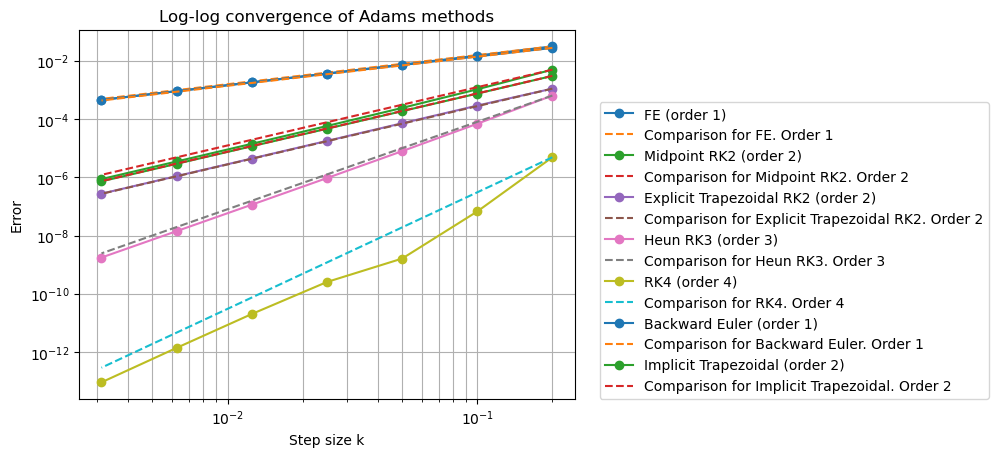

In [674]:
plot_error_methods(one_step_orders, errors)

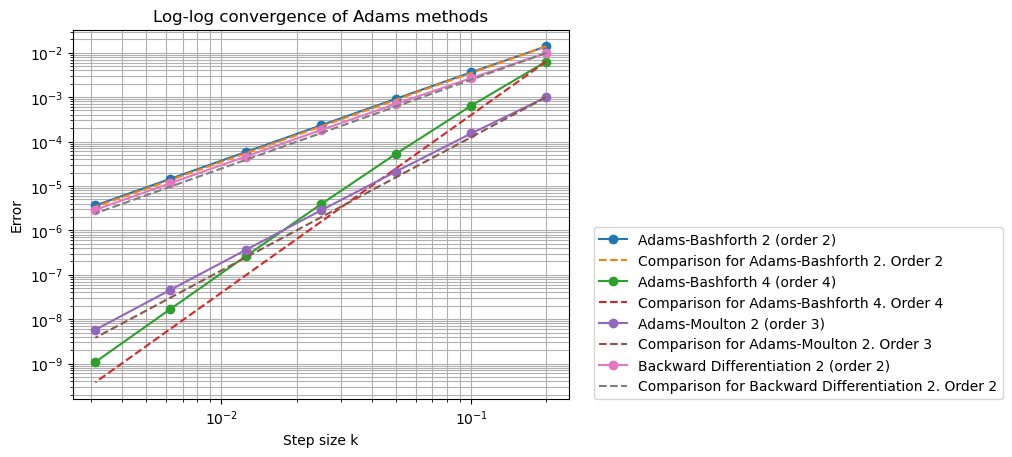

In [675]:
plot_error_methods(multi_step_orders, errors)

### Discussion — Scalar problem
Write your interpretation of the errors and observed orders here.


We see that every method has the order of convergence that we expected.

## Part C — Convergence test 2: a linear system
Use **the same integrators, without changing their implementations**, to solve
$$
\mathbf u'(t)=A\mathbf u(t)+\mathbf g(t),\qquad0\leq t\leq1,
\qquad A=\begin{pmatrix}-2&1\\1&-2\end{pmatrix},
$$
with
$$
\mathbf u(0)=\begin{pmatrix}1\\1\end{pmatrix},\qquad
\mathbf g(t)=\begin{pmatrix}
e^{-t}-\cos t\\
-\sin t-e^{-t}+2\cos t
\end{pmatrix}.
$$
The exact solution is
$$
\boxed{\mathbf u(t)=\begin{pmatrix}e^{-t}\\\cos t\end{pmatrix}.}
$$

### Required results
1. Verify analytically that the proposed solution satisfies the differential equation and initial condition.
2. Define the problem through `f(t, U) = A @ U + g(t)`, with a vector initial state. Evaluate `g` at the time requested by each method, including RK stage times and implicit time levels.
3. For every method, repeat the convergence study with
   $$
   N_m=20\,2^m,\qquad k_m=1/N_m,\qquad m=0,\ldots,6.
   $$
4. Use the final-time error
   $$
   E_m=\|\mathbf U^{N_m}-\mathbf u(1)\|_\infty.
   $$
   Produce the same tables and two log–log plots as in Part B, and compare with the theoretical orders.
5. Plot both components of a representative numerical solution together with their exact solutions. State the method and time step.
6. Explain what changed in your program between the scalar and system experiments. Why should the integrators themselves remain unchanged?

### Connection to linear algebra
For this system, backward Euler is equivalent to
$$
(I-kA)\mathbf U^{n+1}=\mathbf U^n+k\mathbf g(t_{n+1}).
$$
Derive the analogous linear system for BDF2. For one representative step, compare a direct linear solve with the result from your residual-based implementation. Use identical previous states in the comparison and report the difference. Do not form a matrix inverse.

The convergence study must still run through the same general-purpose integrators used in Part B.


1. On the one hand, we have
$$
\mathbf u'(t)=\begin{pmatrix}
-e^{-t}\\
-\sin t
\end{pmatrix}.
$$

So developing the other side of the equation we have

$$
A\mathbf u(t)+\mathbf g(t) = \begin{pmatrix}
-2e^{-t} + \cos t\\
e^{-t} - 2 \cos t
\end{pmatrix}
+
\begin{pmatrix}
e^{-t}-\cos t\\
-\sin t-e^{-t}+2\cos t
\end{pmatrix} 
= 
\begin{pmatrix}
-e^{-t}\\
-\sin t
\end{pmatrix} 
=
\mathbf u'(t)
$$

In [668]:
# Define A, g(t), f(t, U), U0, and the exact solution.
# Reuse all solvers from Part A without changing their code.
# Produce convergence tables, plots, and the linear-solve comparison.

A = np.array([[-2, 1], [1, -2]])
g = lambda t: np.array([np.exp(-t)-np.cos(t), -np.sin(t)-np.exp(-t)+2*np.cos(t)])
f_linear = lambda t, U: A @ U + g(t) # En los métodos A @ U es (2,), no (2, 1). 
# Así que g hay que hacerlo un vector en vez de vector columna.

tspan_linear = (0,1)
U0_linear = np.array([1, 1])
u_exact = lambda t: np.array([np.exp(-t), np.cos(t)])
u_exact_at_1 = u_exact(1)


In [669]:
errors_linear = calculate_errors(methods, f_linear, tspan_linear, U0_linear, N_list, u_exact_at_1)

In [670]:
show_tables(errors_linear)

Table for the method FE. Expected order 1


,m,N,k,Error,Observed Order
0,0,20,0.200000,0.006679,
1,1,40,0.100000,0.003324,1.006536
2,2,80,0.050000,0.001658,1.003363
3,3,160,0.025000,0.000828,1.001702
4,4,320,0.012500,0.000414,1.000856
5,5,640,0.006250,0.000207,1.000429
6,6,1280,0.003125,0.000103,1.000215


Table for the method Midpoint RK2. Expected order 2


,m,N,k,Error,Observed Order
0,0,20,0.200000,2.417577e-04,
1,1,40,0.100000,5.785116e-05,2.063144
2,2,80,0.050000,1.415817e-05,2.030711
3,3,160,0.025000,3.502575e-06,2.015147
4,4,320,0.012500,8.710899e-07,2.007522
5,5,640,0.006250,2.172074e-07,2.003749
6,6,1280,0.003125,5.423146e-08,2.001871


Table for the method Explicit Trapezoidal RK2. Expected order 2


,m,N,k,Error,Observed Order
0,0,20,0.200000,4.061739e-04,
1,1,40,0.100000,9.750023e-05,2.05862
2,2,80,0.050000,2.390074e-05,2.02835
3,3,160,0.025000,5.917715e-06,2.013943
4,4,320,0.012500,1.472355e-06,2.006915
5,5,640,0.006250,3.672113e-07,2.003443
6,6,1280,0.003125,9.169357e-08,2.001718


... (12 outputs left out)

Table for the method Adams-Moulton 2. Expected order 3


,m,N,k,Error,Observed Order
0,0,20,0.200000,2.399480e-06,
1,1,40,0.100000,3.043343e-07,2.978993
2,2,80,0.050000,3.829575e-08,2.990401
3,3,160,0.025000,4.802232e-09,2.995407
4,4,320,0.012500,6.012147e-10,2.997753
5,5,640,0.006250,7.520939e-11,2.998896
6,6,1280,0.003125,9.404366e-12,2.99951


Table for the method Backward Differentiation 2. Expected order 2


,m,N,k,Error,Observed Order
0,0,20,0.200000,1.639855e-04,
1,1,40,0.100000,4.114108e-05,1.994917
2,2,80,0.050000,1.029769e-05,1.998258
3,3,160,0.025000,2.575683e-06,1.999294
4,4,320,0.012500,6.440615e-07,1.999685
5,5,640,0.006250,1.610320e-07,1.999851
6,6,1280,0.003125,4.026001e-08,1.999928


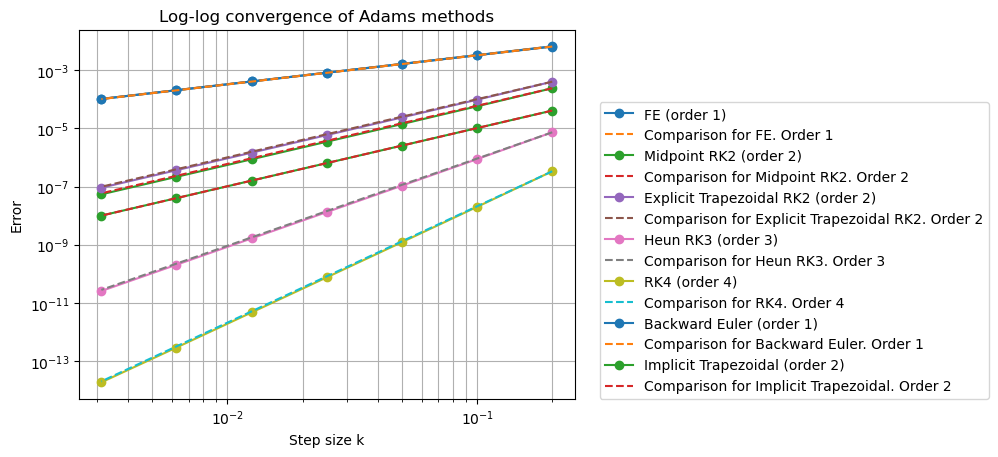

In [676]:
plot_error_methods(one_step_orders, errors_linear)

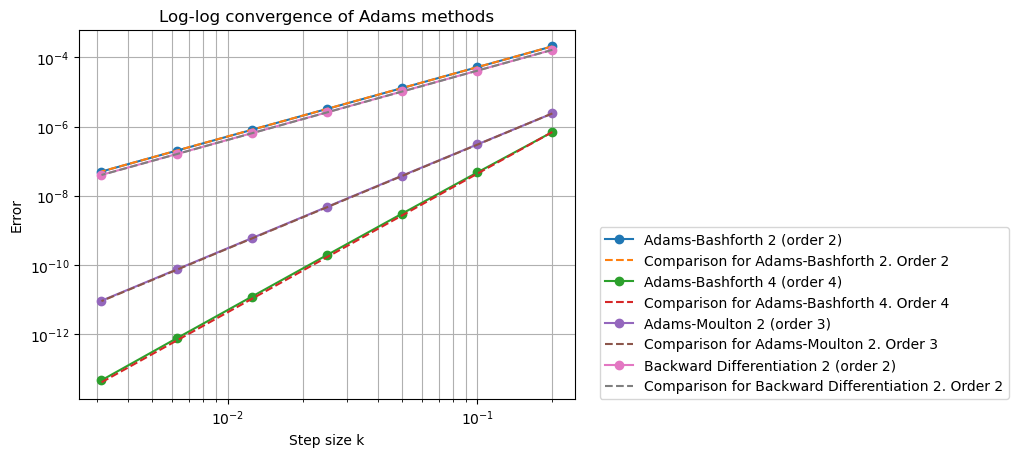

In [678]:
plot_error_methods(multi_step_orders, errors_linear)

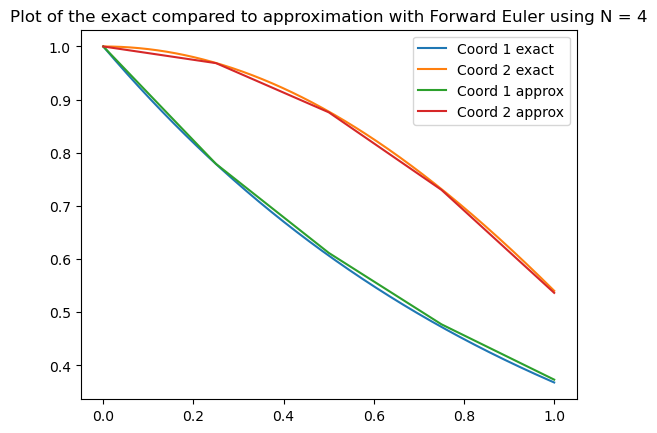

In [697]:

N = 4


t, sol = ab2(f_linear, tspan_linear, U0_linear, N)

t_cont= np.linspace(tspan_linear[0], tspan_linear[1], 500)
plt.plot(t_cont, u_exact(t_cont)[0], label = "Coord 1 exact")
plt.plot(t_cont, u_exact(t_cont)[1], label = "Coord 2 exact")

plt.plot(t, sol[0], label = "Coord 1 approx")
plt.plot(t, sol[1], label = "Coord 2 approx")

plt.title(f"Plot of the exact compared to approximation with Forward Euler using N = {N}")
plt.legend()

plt.show()

The plot is done taking a so small $N$ to distinguish the exact function and its approximation. Despite taking the method with the lowest convergence ratio, Forward Euler cannot be distinguished in the plot even with small values of $N$ like $N\geq 10$.

### Discussion — System problem
Compare the observed orders with those from the scalar problem. Explain how your interface supports both cases.


The observed orders coincide with the ones of the scalar problem, which are also the same as the theoretical ones. The interface support both cases because we do not use the length of the vectors for anything, and this is allowed because of how the numpy arrays work, as otherwise we would have to do the operations using for loops. 

## Submission
Submit this notebook with:
- your implementations of all eleven methods and their RK4 initialization routine (or an accompanying Python module imported here);
- convergence tables and plots for both test problems;
- the representative two-component solution plot and the implicit-step comparison;
- a short discussion of theoretical versus observed orders, initialization, and algebraic solver tolerance.

Run the completed notebook from top to bottom in a fresh kernel before submitting. Exact solutions belong in the test code, not inside the integrators.

## Why this will be useful later
In the method of lines, spatial discretization often produces
$$
\mathbf U'(t)=A\mathbf U(t)+\mathbf g(t)
$$
or a nonlinear vector right-hand side. Your integrators can advance these systems by receiving a new `f(t, U)` and initial vector. Later, we will study stability restrictions, efficient matrix solves, finite element mass matrices, and spectral discretizations; none of those additional topics is required in this assignment.
